In [1]:
print("CELL 1: IMPORT LIBRARIES")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

CELL 1: IMPORT LIBRARIES


In [2]:
print("CELL 2: LOAD THE DATASET")
housing = fetch_california_housing(as_frame=True)

df = housing.frame.rename(columns={"MedHouseVal": "median_house_value"}).copy()

print("Dataset loaded successfully.")
print("Dataset name: California Housing")
display(df.head())

CELL 2: LOAD THE DATASET
Dataset loaded successfully.
Dataset name: California Housing


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,median_house_value
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("CELL 3: DATASET DESCRIPTION")
print("Number of records:", df.shape[0])
print("Number of attributes:", df.shape[1])
print("Predictor attributes:", len(housing.feature_names))
print("Target variable: median_house_value")
print("Target range (units of $100,000):", df["median_house_value"].min(), "to", df["median_house_value"].max())
print("Dataset description:")
print(housing.DESCR[:1800])

CELL 3: DATASET DESCRIPTION
Number of records: 20640
Number of attributes: 9
Predictor attributes: 8
Target variable: median_house_value
Target range (units of $100,000): 0.14999 to 5.00001
Dataset description:
.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housin

In [4]:
print("CELL 4: INSPECT DATASET STRUCTURE")
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nDataset information:")
df.info()

CELL 4: INSPECT DATASET STRUCTURE
Dataset dimensions: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'median_house_value']

Data types:
MedInc                float64
HouseAge              float64
AveRooms              float64
AveBedrms             float64
Population            float64
AveOccup              float64
Latitude              float64
Longitude             float64
median_house_value    float64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   MedInc              20640 non-null  float64
 1   HouseAge            20640 non-null  float64
 2   AveRooms            20640 non-null  float64
 3   AveBedrms           20640 non-null  float64
 4   Population          20640 non-null  float64
 5   AveOccup            2064

In [5]:
print("CELL 5: SUMMARY STATISTICS")
display(df.describe().T)

CELL 5: SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
median_house_value,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [6]:
print("CELL 6: CHECK MISSING VALUES")
missing_values = df.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})
display(missing_summary[missing_summary["Missing Values"] >= 0])

print("Total missing values:", int(df.isnull().sum().sum()))

CELL 6: CHECK MISSING VALUES


,Missing Values,Missing Percentage
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
median_house_value,0,0.0


Total missing values: 0


In [7]:
print("CELL 7: HANDLE MISSING VALUES")
df_clean = df.copy()

numeric_columns = df_clean.select_dtypes(include=np.number).columns
for column in numeric_columns:
    if df_clean[column].isnull().any():
        df_clean[column] = df_clean[column].fillna(df_clean[column].median())

print("Missing-value handling completed.")
print("Remaining missing values:", int(df_clean.isnull().sum().sum()))

CELL 7: HANDLE MISSING VALUES
Missing-value handling completed.
Remaining missing values: 0


In [8]:
print("CELL 8: CHECK AND REMOVE DUPLICATES")
duplicate_count = df_clean.duplicated().sum()
print("Duplicate records found:", duplicate_count)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Dataset dimensions after duplicate removal:", df_clean.shape)
print("Remaining duplicate records:", df_clean.duplicated().sum())

CELL 8: CHECK AND REMOVE DUPLICATES
Duplicate records found: 0
Dataset dimensions after duplicate removal: (20640, 9)
Remaining duplicate records: 0


In [9]:
print("CELL 9: CHECK INCONSISTENT DATA")
print("Target range (median_house_value):", df_clean["median_house_value"].min(), "to", df_clean["median_house_value"].max())

ceiling_count = (df_clean["median_house_value"] == 5.0).sum()
print("Records at the 5.0 ceiling:", int(ceiling_count), f"({ceiling_count / len(df_clean) * 100:.2f}%)")

print("\nCheck for infinite numeric values:")
infinite_count = np.isinf(df_clean.select_dtypes(include=np.number)).sum().sum()
print("Infinite values found:", int(infinite_count))

CELL 9: CHECK INCONSISTENT DATA
Target range (median_house_value): 0.14999 to 5.00001
Records at the 5.0 ceiling: 27 (0.13%)

Check for infinite numeric values:
Infinite values found: 0


In [10]:
print("CELL 10: HANDLE INFINITE VALUES")
numeric_columns = df_clean.select_dtypes(include=np.number).columns

df_clean[numeric_columns] = df_clean[numeric_columns].replace(
    [np.inf, -np.inf], np.nan
)

for column in numeric_columns:
    if df_clean[column].isnull().any():
        df_clean[column] = df_clean[column].fillna(df_clean[column].median())

print("Infinite-value handling completed.")
print("Remaining infinite values:", int(np.isinf(df_clean[numeric_columns]).sum().sum()))
print("Remaining missing values:", int(df_clean.isnull().sum().sum()))

CELL 10: HANDLE INFINITE VALUES
Infinite-value handling completed.
Remaining infinite values: 0
Remaining missing values: 0


In [11]:
print("CELL 11: IDENTIFY OUTLIERS USING THE IQR METHOD")
outlier_results = []

for column in numeric_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_count = ((df_clean[column] < lower_bound) |
                     (df_clean[column] > upper_bound)).sum()

    outlier_results.append({
        "Attribute": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outlier_count)
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

CELL 11: IDENTIFY OUTLIERS USING THE IQR METHOD


,Attribute,Lower Bound,Upper Bound,Outlier Count
0,MedInc,-0.706375,8.013025,681
1,HouseAge,-10.500000,65.500000,0
2,AveRooms,2.023219,8.469878,511
3,AveBedrms,0.865909,1.239697,1424
4,Population,-620.000000,3132.000000,1196
5,AveOccup,1.150961,4.561041,711
6,Latitude,28.260000,43.380000,0
7,Longitude,-127.485000,-112.325000,0
8,median_house_value,-0.980875,4.824125,1071


CELL 12: VISUALIZE OUTLIERS


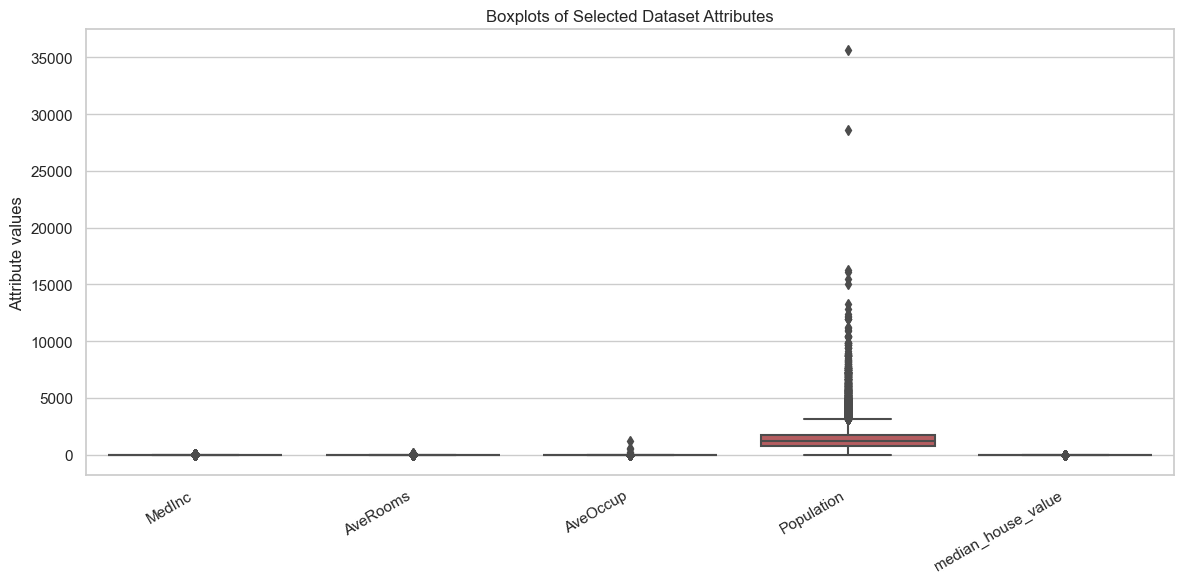

In [12]:
print("CELL 12: VISUALIZE OUTLIERS")
selected_features = [
    "MedInc",
    "AveRooms",
    "AveOccup",
    "Population",
    "median_house_value"
]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean[selected_features])
plt.title("Boxplots of Selected Dataset Attributes")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Attribute values")
plt.tight_layout()
plt.show()

In [13]:
print("CELL 13: REVIEW NOISY DATA")
print("Minimum values for numeric attributes:")
display(df_clean[numeric_columns].min().to_frame("Minimum"))

print("\nMaximum values for numeric attributes:")
display(df_clean[numeric_columns].max().to_frame("Maximum"))

print("\nStandard deviations:")
display(df_clean[numeric_columns].std().to_frame("Standard Deviation"))

print("Outliers are flagged for review. Extreme values are not automatically removed because they may represent genuine block-group averages, such as sparsely populated areas.")

CELL 13: REVIEW NOISY DATA
Minimum values for numeric attributes:


,Minimum
MedInc,0.499900
HouseAge,1.000000
AveRooms,0.846154
AveBedrms,0.333333
Population,3.000000
AveOccup,0.692308
Latitude,32.540000
Longitude,-124.350000
median_house_value,0.149990



Maximum values for numeric attributes:


,Maximum
MedInc,15.000100
HouseAge,52.000000
AveRooms,141.909091
AveBedrms,34.066667
Population,35682.000000
AveOccup,1243.333333
Latitude,41.950000
Longitude,-114.310000
median_house_value,5.000010



Standard deviations:


,Standard Deviation
MedInc,1.899822
HouseAge,12.585558
AveRooms,2.474173
AveBedrms,0.473911
Population,1132.462122
AveOccup,10.386050
Latitude,2.135952
Longitude,2.003532
median_house_value,1.153956


Outliers are flagged for review. Extreme values are not automatically removed because they may represent genuine block-group averages, such as sparsely populated areas.


CELL 14: CHECK DATA DISTRIBUTION


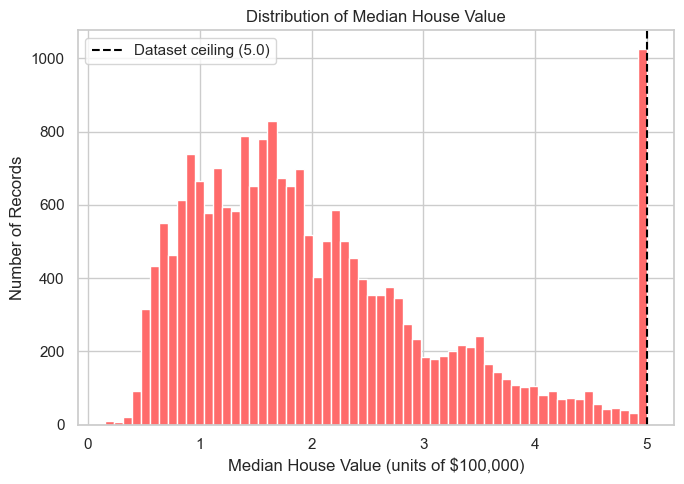

,median_house_value
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


In [14]:
print("CELL 14: CHECK DATA DISTRIBUTION")
plt.figure(figsize=(7, 5))
plt.hist(df_clean["median_house_value"], bins=60, color="#FF6B6B", edgecolor="white")
plt.axvline(5.0, color="black", linestyle="--", linewidth=1.5, label="Dataset ceiling (5.0)")
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value (units of $100,000)")
plt.ylabel("Number of Records")
plt.legend()
plt.tight_layout()
plt.show()

display(df_clean["median_house_value"].describe().to_frame("median_house_value"))

CELL 15: HISTOGRAMS OF SELECTED ATTRIBUTES


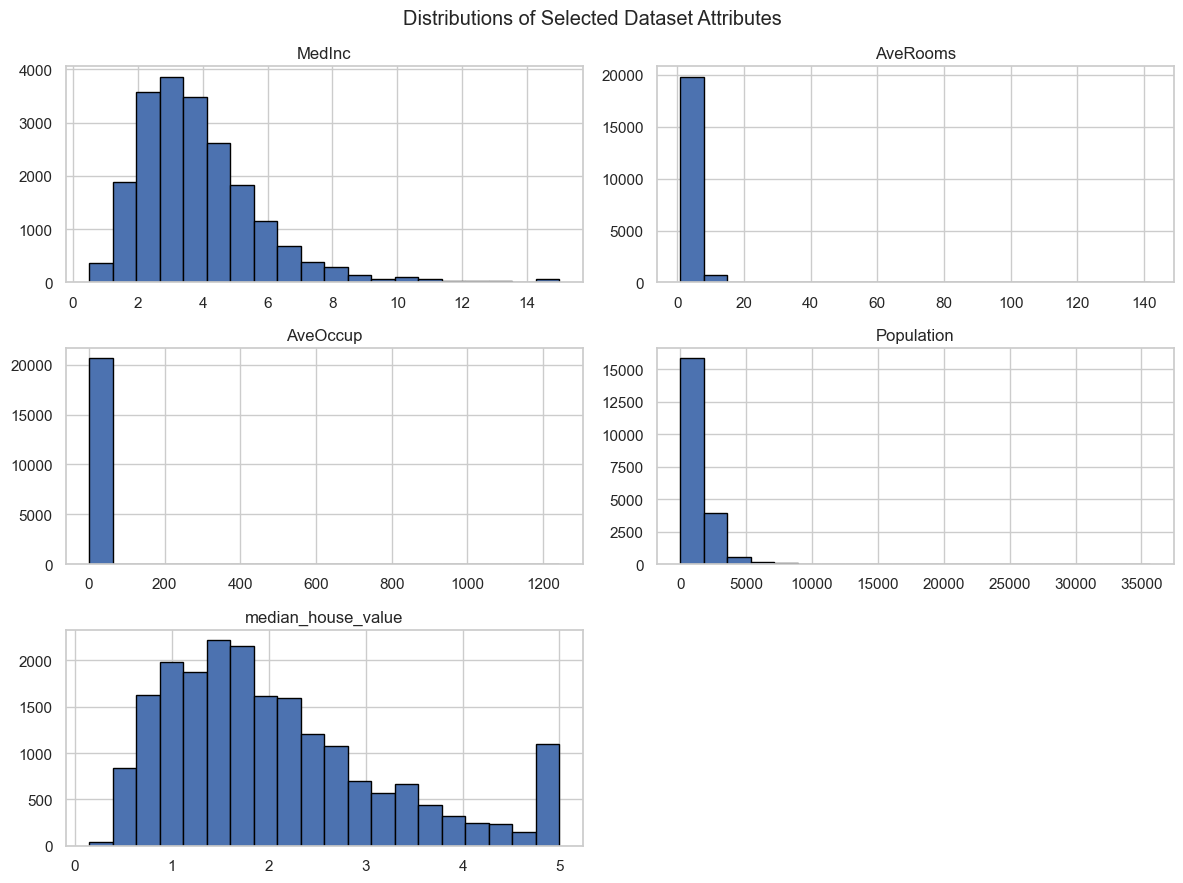

In [15]:
print("CELL 15: HISTOGRAMS OF SELECTED ATTRIBUTES")
df_clean[selected_features].hist(figsize=(12, 9), bins=20, edgecolor="black")
plt.suptitle("Distributions of Selected Dataset Attributes")
plt.tight_layout()
plt.show()

CELL 16: CORRELATION ANALYSIS


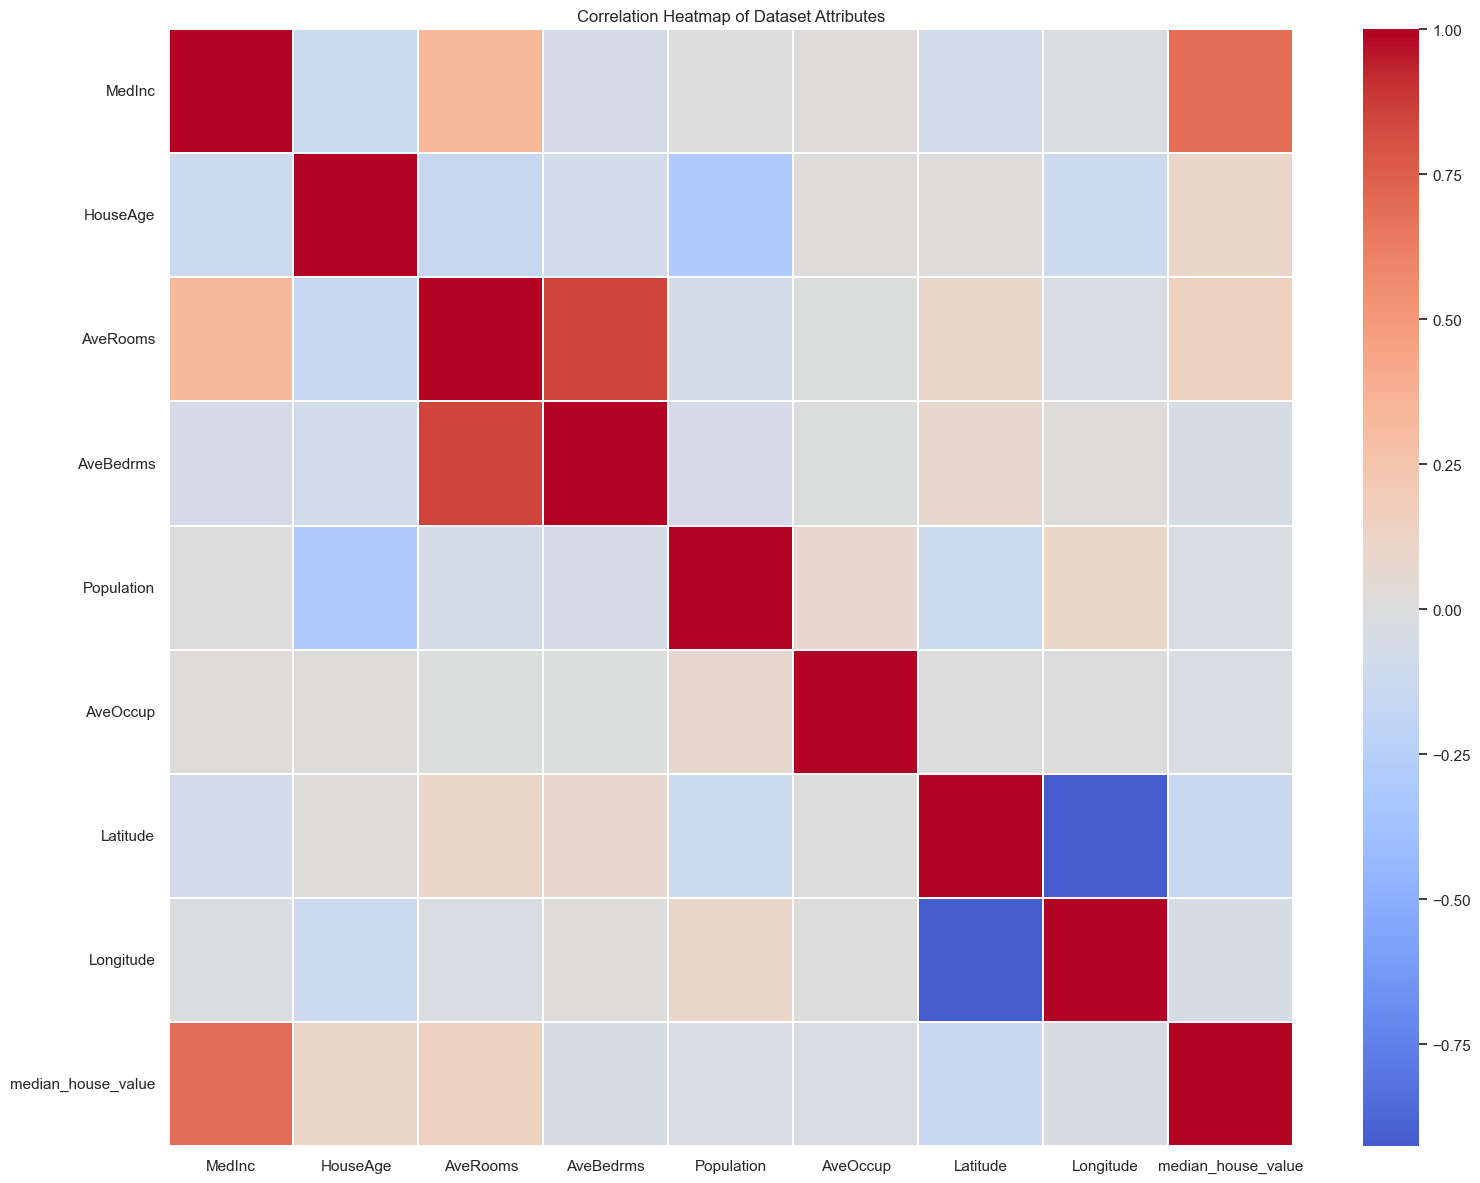

In [16]:
print("CELL 16: CORRELATION ANALYSIS")
correlation_matrix = df_clean[numeric_columns].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)
plt.title("Correlation Heatmap of Dataset Attributes")
plt.tight_layout()
plt.show()

In [17]:
print("CELL 17: IDENTIFY STRONG FEATURE RELATIONSHIPS")
correlation_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack().reset_index()

correlation_pairs.columns = ["Attribute 1", "Attribute 2", "Correlation"]
correlation_pairs["Absolute Correlation"] = correlation_pairs["Correlation"].abs()

display(
    correlation_pairs.sort_values(
        "Absolute Correlation", ascending=False
    ).head(15)
)

CELL 17: IDENTIFY STRONG FEATURE RELATIONSHIPS


,Attribute 1,Attribute 2,Correlation,Absolute Correlation
33,Latitude,Longitude,-0.924664,0.924664
15,AveRooms,AveBedrms,0.847621,0.847621
7,MedInc,median_house_value,0.688075,0.688075
1,MedInc,AveRooms,0.326895,0.326895
10,HouseAge,Population,-0.296244,0.296244
8,HouseAge,AveRooms,-0.153277,0.153277
20,AveRooms,median_house_value,0.151948,0.151948
34,Latitude,median_house_value,-0.144160,0.144160
0,MedInc,HouseAge,-0.119034,0.119034
27,Population,Latitude,-0.108785,0.108785


CELL 18: COMPARE SELECTED ATTRIBUTES BY HOUSE VALUE BAND


/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


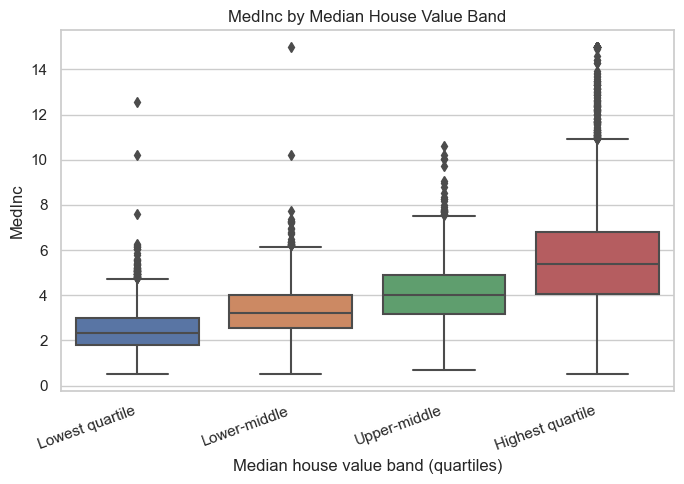

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


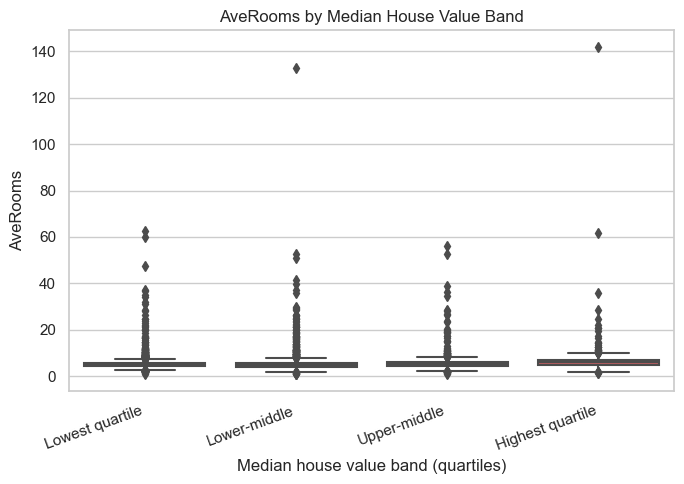

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


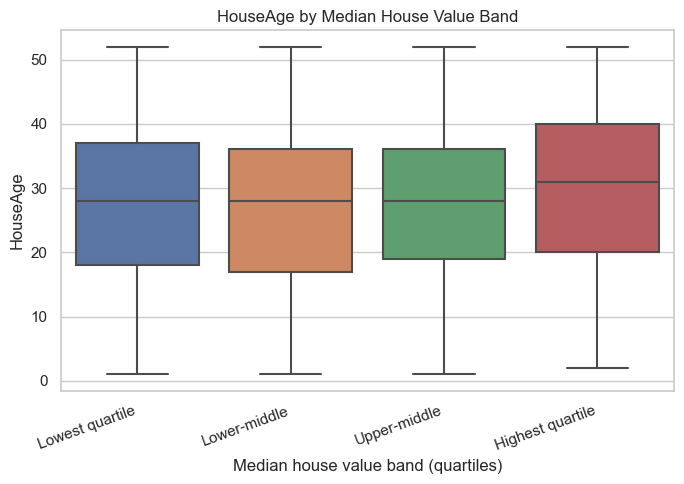

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


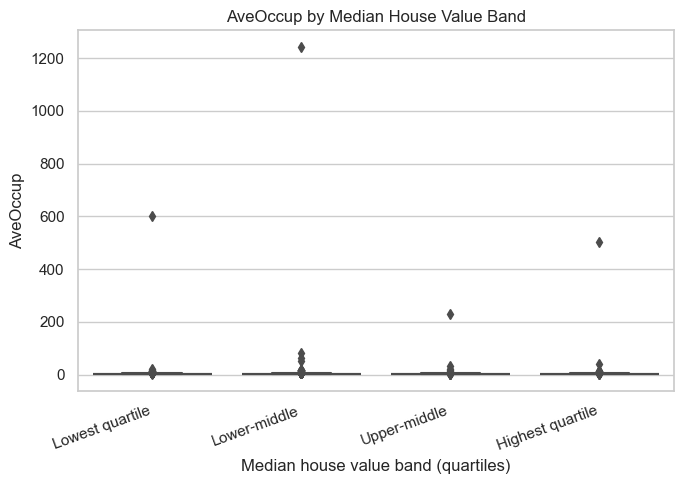

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


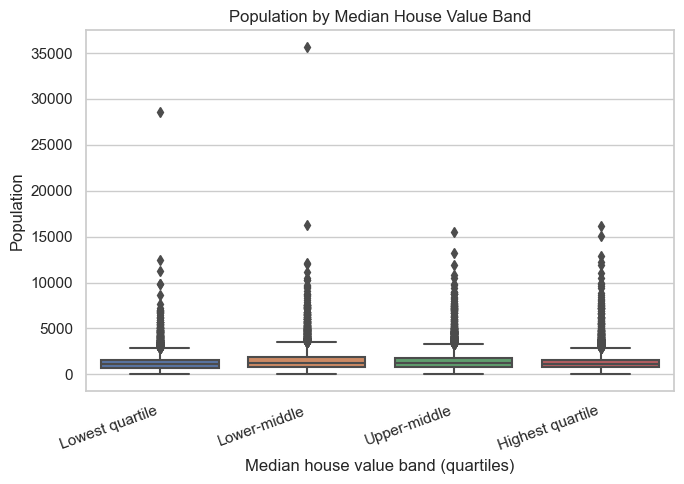

In [18]:
print("CELL 18: COMPARE SELECTED ATTRIBUTES BY HOUSE VALUE BAND")
comparison_features = [
    "MedInc",
    "AveRooms",
    "HouseAge",
    "AveOccup",
    "Population"
]

df_bands = df_clean.copy()
df_bands["value_band"] = pd.qcut(
    df_bands["median_house_value"], q=4,
    labels=["Lowest quartile", "Lower-middle", "Upper-middle", "Highest quartile"]
)

for feature in comparison_features:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df_bands, x="value_band", y=feature)
    plt.title(f"{feature} by Median House Value Band")
    plt.xlabel("Median house value band (quartiles)")
    plt.ylabel(feature)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

In [19]:
print("CELL 19: FINAL CLEANED DATASET")
print("Final dataset dimensions:", df_clean.shape)
print("Total missing values:", int(df_clean.isnull().sum().sum()))
print("Total duplicate records:", int(df_clean.duplicated().sum()))

print("\nFinal data types:")
display(df_clean.dtypes.to_frame("Data Type"))

print("\nFirst five cleaned records:")
display(df_clean.head())

CELL 19: FINAL CLEANED DATASET
Final dataset dimensions: (20640, 9)
Total missing values: 0
Total duplicate records: 0

Final data types:


,Data Type
MedInc,float64
HouseAge,float64
AveRooms,float64
AveBedrms,float64
Population,float64
AveOccup,float64
Latitude,float64
Longitude,float64
median_house_value,float64



First five cleaned records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,median_house_value
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [20]:
print("CELL 20: SAVE THE CLEANED DATASET")
output_file = "california_housing_cleaned.csv"
df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved as:", output_file)

CELL 20: SAVE THE CLEANED DATASET
Cleaned dataset saved as: california_housing_cleaned.csv


In [21]:
print("CELL 21: KEY EXPLORATORY DATA ANALYSIS INSIGHTS")
target = df_clean["median_house_value"]

print("1. Dataset size:", df_clean.shape[0], "records and", df_clean.shape[1], "columns.")
print("2. Median house value (units of $100,000): mean", round(target.mean(), 3), "| median", round(target.median(), 3))
print("3. Records at the 5.0 ceiling:", int((target == 5.0).sum()))
print("4. Correlation of median income with house value:", round(df_clean["MedInc"].corr(target), 3))
print("5. Missing values remaining:", int(df_clean.isnull().sum().sum()))
print("6. Duplicate records remaining:", int(df_clean.duplicated().sum()))

CELL 21: KEY EXPLORATORY DATA ANALYSIS INSIGHTS
1. Dataset size: 20640 records and 9 columns.
2. Median house value (units of $100,000): mean 2.069 | median 1.797
3. Records at the 5.0 ceiling: 27
4. Correlation of median income with house value: 0.688
5. Missing values remaining: 0
6. Duplicate records remaining: 0


In [22]:
print("CELL 22: PROJECT DELIVERABLE 1 COMPLETION")
print("Deliverable 1: Data Collection, Cleaning, and Exploration")
print("Dataset: California Housing")
print("Completed tasks:")
print("1. Selected and described the dataset.")
print("2. Loaded the dataset using Pandas.")
print("3. Inspected the dataset structure and summary statistics.")
print("4. Checked and handled missing values.")
print("5. Checked and removed duplicate records.")
print("6. Checked inconsistent and infinite values.")
print("7. Identified potential outliers using the IQR method.")
print("8. Created visualizations of distributions and outliers.")
print("9. Examined correlations and compared attributes across house value bands.")
print("10. Saved the cleaned dataset as california_housing_cleaned.csv.")

CELL 22: PROJECT DELIVERABLE 1 COMPLETION
Deliverable 1: Data Collection, Cleaning, and Exploration
Dataset: California Housing
Completed tasks:
1. Selected and described the dataset.
2. Loaded the dataset using Pandas.
3. Inspected the dataset structure and summary statistics.
4. Checked and handled missing values.
5. Checked and removed duplicate records.
6. Checked inconsistent and infinite values.
7. Identified potential outliers using the IQR method.
8. Created visualizations of distributions and outliers.
9. Examined correlations and compared attributes across house value bands.
10. Saved the cleaned dataset as california_housing_cleaned.csv.
